# Temporal persistence — retention curves (figure & table)

Pooled recompute from the per-condition cache `results/temporal_persistence/<model>/cond_*.pt` (robust to which datatype process wrote summary.json). cos(pivot goal-encoding, encoding at x% of the implementation) over relation masks. **teal = same sub-goal (signal); orange = different sub-goal (baseline); dashed = cross-language.** Saves to `notebooks/Figures/temporal_persistence/`.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))
import glob, torch
import numpy as np, matplotlib.pyplot as plt
import figstyle as F; F.set_style()
from src.goals import temporal_persistence as TP
from rich import print as rich_print
from rich.table import Table
GROUP='temporal_persistence'; SLUG='Qwen2.5-Coder-32B-Instruct'
cdir=TP.cache_dir(SLUG)
recs=[torch.load(p)['record'] for p in glob.glob(os.path.join(cdir,'cond_*.pt'))]
from collections import Counter
per_cell=dict(Counter(f"{r['datatype']}/{r['lang']}" for r in recs))
grid=TP.DEFAULT_PROG_GRID
curves=TP.compute_curves(recs, grid, collapse_lang=True)  # ii+ii*, iv+iv* pooled
print(f'{len(recs)} conditions | per-cell {per_cell}')

1708 conditions | per-cell {'int/cpp': 167, 'str/python': 225, 'list[int]/python': 238, 'list[int]/cpp': 185, 'list[str]/python': 371, 'int/python': 288, 'str/cpp': 175, 'list[str]/cpp': 59}


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/temporal_persistence/retention_curves_sem.pdf


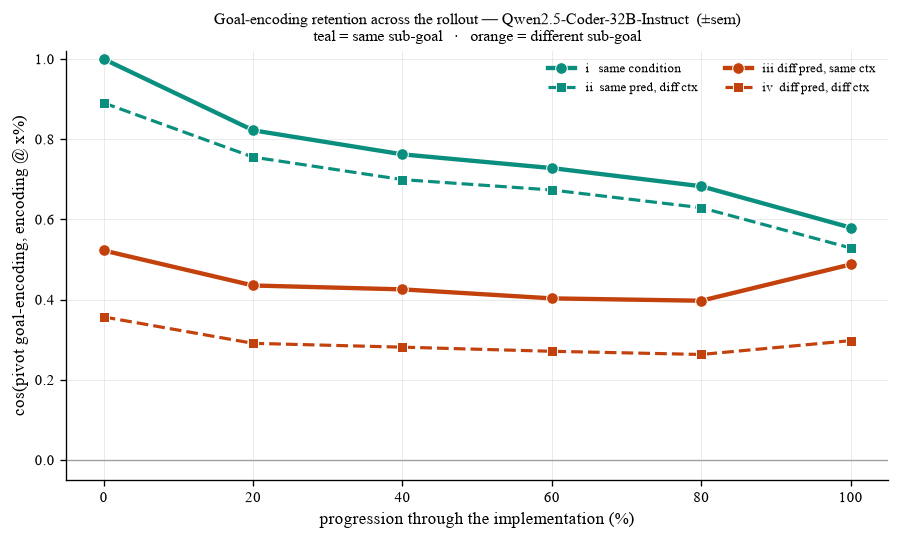

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/temporal_persistence/retention_curves_std.pdf


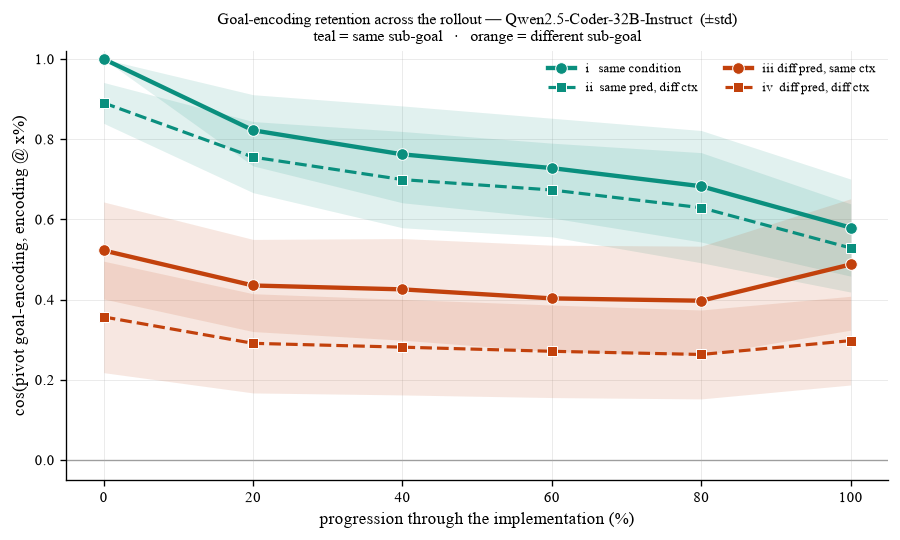

In [2]:
# 4-mask retention (cross-lang collapsed): teal=same sub-goal, orange=different sub-goal.
T,O=F.TP_TEAL,F.TP_ORANGE
STYLE={
 'i   same condition':      (T,'-','o',2.6,7),
 'ii  same pred, diff ctx': (T,'--','s',1.9,6),
 'iii diff pred, same ctx': (O,'-','o',2.6,7),
 'iv  diff pred, diff ctx': (O,'--','s',1.9,6)}
for err in ['sem','std']:
    fig,ax=plt.subplots(figsize=(7.6,4.6)); xs=[p*100 for p in grid]
    for name,cur in curves.items():
        color,ls,mk,lw,ms=STYLE.get(name,('grey','-','o',1.5,5))
        mu=np.array([cur[p]['mean'] for p in grid]); er=np.array([cur[p][err] for p in grid])
        ax.plot(xs,mu,ls=ls,marker=mk,color=color,lw=lw,markersize=ms,
                markeredgecolor='white',markeredgewidth=0.6,label=name,zorder=3)
        ax.fill_between(xs,mu-er,mu+er,color=color,alpha=0.12,lw=0,zorder=1)
    ax.axhline(0,color='#999',lw=.8,zorder=0)
    ax.set_xlabel('progression through the implementation (%)')
    ax.set_ylabel('cos(pivot goal-encoding, encoding @ x%)'); ax.set_ylim(top=1.02)
    ax.set_title(f'Goal-encoding retention across the rollout — {SLUG}  (\u00b1{err})\n'
                 f'teal = same sub-goal   \u00b7   orange = different sub-goal',fontsize=9.5)
    ax.legend(fontsize=8,ncol=2,frameon=False,loc='upper right')
    fig.tight_layout(); print('saved',F.save_fig(fig,GROUP,f'retention_curves_{err}')); plt.show()

                     Retention cos(pivot, enc @ x%) — 1708 conditions                      
┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┓
┃ comparison              ┃       n ┃     0% ┃    20% ┃    40% ┃    60% ┃    80% ┃   100% ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━┩
│ i   same condition      │    1708 │ +1.000 │ +0.822 │ +0.762 │ +0.728 │ +0.683 │ +0.580 │
│ ii  same pred, diff ctx │   49940 │ +0.891 │ +0.755 │ +0.699 │ +0.673 │ +0.629 │ +0.529 │
│ iii diff pred, same ctx │    1926 │ +0.522 │ +0.435 │ +0.425 │ +0.403 │ +0.397 │ +0.488 │
│ iv  diff pred, diff ctx │ 2863690 │ +0.357 │ +0.291 │ +0.281 │ +0.271 │ +0.263 │ +0.298 │
└─────────────────────────┴─────────┴────────┴────────┴────────┴────────┴────────┴────────┘

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/temporal_persistence/retention_table.tex


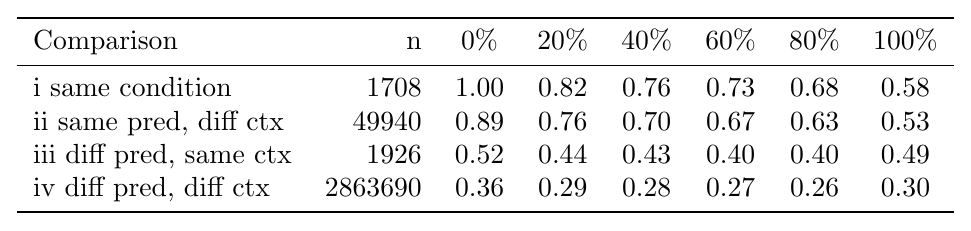

In [3]:
# table of the pooled curves + .tex
t=Table(title=f'Retention cos(pivot, enc @ x%) — {len(recs)} conditions')
t.add_column('comparison'); t.add_column('n',justify='right')
[t.add_column(f'{int(p*100)}%',justify='right') for p in grid]
for name,cur in curves.items():
    t.add_row(name, str(cur[grid[0]]['n']), *[f"{cur[p]['mean']:+.3f}" for p in grid])
rich_print(t)
hdr=' & '.join(['Comparison','n']+[f'{int(p*100)}\\%' for p in grid])
body=' \\\\\n'.join(name.replace('*','$^*$')+f" & {cur[grid[0]]['n']} & "+' & '.join(f"{cur[p]['mean']:.2f}" for p in grid) for name,cur in curves.items())
tex='\\begin{tabular}{lr'+'c'*len(grid)+'}\n\\toprule\n'+hdr+' \\\\\n\\midrule\n'+body+' \\\\\n\\bottomrule\n\\end{tabular}'
print('wrote',F.save_table(tex,GROUP,'retention_table'))
img=F.render_latex_table(tex); img if img is not None else rich_print('[dim](latex preview unavailable)[/dim]')